# Livrable 2 : données, traitement et découpage


# Partie 1 : chargement et exploration des données brutes

## 1.1 Chargement

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

X = pd.read_csv("../data/raw/train_values.csv")  # variables
y = pd.read_csv("../data/raw/train_labels.csv")  # étiquettes

print("Mêmes id :", (X["id"] == y["id"]).all())
df = X.merge(y, on="id")
df.shape

Mêmes id : True


(59400, 41)

## 1.2 Aperçu : vingt exemples au hasard

In [2]:
# Tirage différent à chaque exécution : on voit les données telles qu'elles sont, défauts compris
df.sample(20)

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
13309,57879,2000.0,2011-02-21,Danida,1911,DWE,35.534504,-8.281609,none,0,...,soft,good,seasonal,seasonal,hand dtw,borehole,groundwater,hand pump,hand pump,functional
47450,38571,0.0,2011-03-16,Water,0,Gove,35.666989,-5.949029,Shulen,0,...,soft,good,enough,enough,machine dbh,borehole,groundwater,communal standpipe,communal standpipe,functional
12252,37421,500.0,2011-03-23,Is,283,Is,37.036236,-7.691151,Mskitini,0,...,salty,salty,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional
26318,3034,0.0,2011-03-21,Water,0,Gover,36.272577,-6.732574,Kwa Korneli,0,...,soft,good,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump,functional
6849,67490,0.0,2011-04-13,Adb,1781,DWE,34.689092,-9.160716,Kwa Simangwa,0,...,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe,functional
12649,56294,0.0,2013-01-23,Finn Water,475,FINN WATER,37.844289,-9.754328,Mmawa,0,...,soft,good,dry,dry,shallow well,shallow well,groundwater,other,other,non functional
24967,20472,200.0,2013-01-18,Dwe,1235,DWE,30.323407,-4.310061,Kwa Edson,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
23370,9869,0.0,2011-03-11,Government Of Tanzania,304,DWE,38.619120,-5.215019,Kwamkai,0,...,soft,good,seasonal,seasonal,spring,spring,groundwater,communal standpipe multiple,communal standpipe,functional
16710,25453,0.0,2011-04-18,Kkkt,0,KKKT,32.941756,-9.161983,Happy Mwembe,0,...,soft,good,insufficient,insufficient,shallow well,shallow well,groundwater,hand pump,hand pump,non functional
56037,10617,0.0,2011-08-26,Rudep,1956,DWE,31.827116,-8.183571,Maweni,0,...,soft,good,insufficient,insufficient,spring,spring,groundwater,communal standpipe,communal standpipe,non functional


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  str    
 3   funder                 55763 non-null  str    
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  str    
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  str    
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  str    
 11  subvillage             59029 non-null  str    
 12  region                 59400 non-null  str    
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lga          

## 1.3 Variable cible

status_group
functional                 0.543
non functional             0.384
functional needs repair    0.073
Name: proportion, dtype: float64


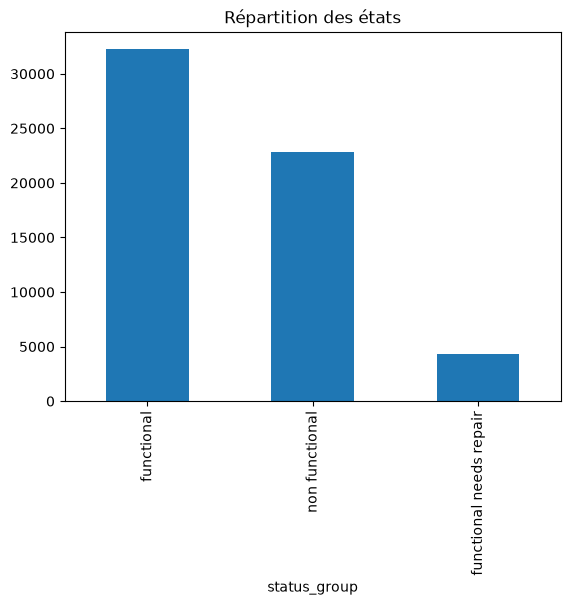

In [4]:
print(df["status_group"].value_counts(normalize=True).round(3))
df["status_group"].value_counts().plot.bar(title="Répartition des états")
plt.show()

## 1.4 Variables numériques

In [5]:
num = ["amount_tsh", "gps_height", "longitude", "latitude", "num_private",
       "region_code", "district_code", "population", "construction_year"]
df[num].describe().round(1)

,amount_tsh,gps_height,longitude,latitude,num_private,region_code,district_code,population,construction_year
count,59400.0,59400.0,59400.0,59400.0,59400.0,59400.0,59400.0,59400.0,59400.0
mean,317.7,668.3,34.1,-5.7,0.5,15.3,5.6,179.9,1300.7
std,2997.6,693.1,6.6,2.9,12.2,17.6,9.6,471.5,951.6
min,0.0,-90.0,0.0,-11.6,0.0,1.0,0.0,0.0,0.0
25%,0.0,0.0,33.1,-8.5,0.0,5.0,2.0,0.0,0.0
50%,0.0,369.0,34.9,-5.0,0.0,12.0,3.0,25.0,1986.0
75%,20.0,1319.2,37.2,-3.3,0.0,17.0,5.0,215.0,2004.0
max,350000.0,2770.0,40.3,-0.0,1776.0,99.0,80.0,30500.0,2013.0


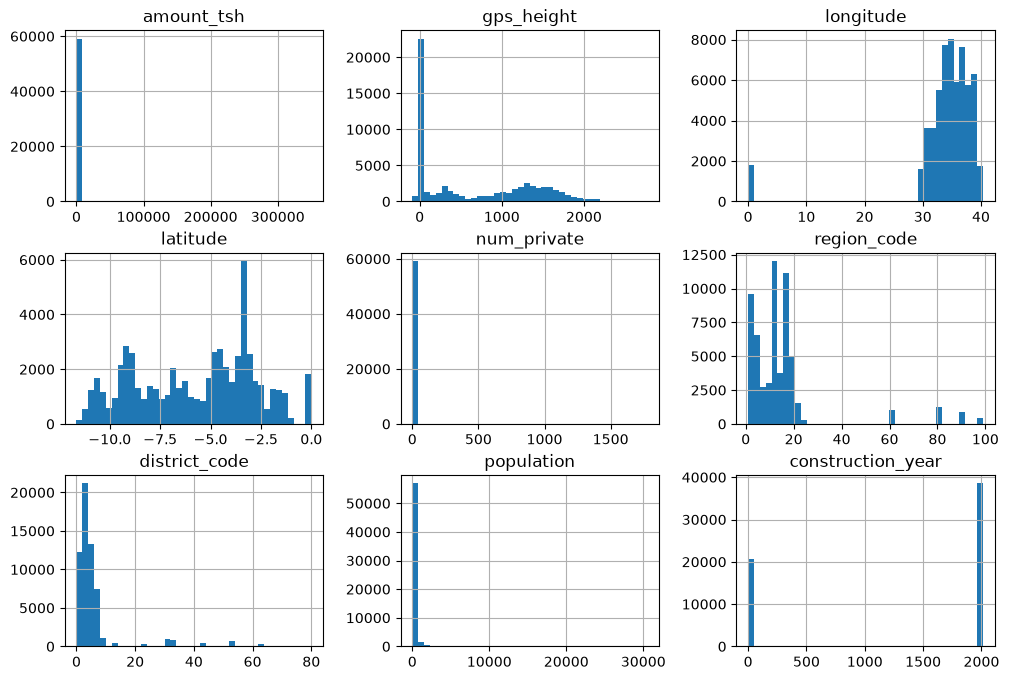

In [6]:
df[num].hist(bins=40, figsize=(12, 8))
plt.show()

In [7]:
# Part de zéros (%)
((df[num] == 0).mean() * 100).round(1)

amount_tsh           70.1
gps_height           34.4
longitude             3.1
latitude              0.0
num_private          98.7
region_code           0.0
district_code         0.0
population           36.0
construction_year    34.9
dtype: float64

## 1.5 Variables catégorielles

In [8]:
cat = [c for c in df.columns if c not in num + ["id", "status_group"]]
df[cat].nunique().sort_values(ascending=False)

wpt_name                 37399
subvillage               19287
scheme_name               2695
installer                 2145
ward                      2092
funder                    1896
date_recorded              356
lga                        125
region                      21
extraction_type             18
extraction_type_group       13
management                  12
scheme_management           11
source                      10
basin                        9
water_quality                8
payment_type                 7
source_type                  7
waterpoint_type              7
extraction_type_class        7
payment                      7
waterpoint_type_group        6
quality_group                6
management_group             5
quantity_group               5
quantity                     5
source_class                 3
public_meeting               2
permit                       2
recorded_by                  1
dtype: int64

In [9]:
# Extrême 1 : la variable qui a le moins de modalités (trouvée automatiquement)
modalites = df[cat].nunique()
moins = modalites.idxmin()
print(moins, ":", modalites[moins], "valeur(s)")
print(df[moins].value_counts(), "\n")

# Extrême 2 : installer, plus de 2 000 modalités ; on y voit aussi des écritures différentes
# d'un même nom (DWE, Government / Central government) et un faux manquant « 0 »
print(df["installer"].value_counts().head(10))

recorded_by : 1 valeur(s)
recorded_by
GeoData Consultants Ltd    59400
Name: count, dtype: int64 

installer
DWE                   17402
Government             1825
RWE                    1206
Commu                  1060
DANIDA                 1050
KKKT                    898
Hesawa                  840
0                       777
TCRS                    707
Central government      622
Name: count, dtype: int64


## 1.6 Valeurs manquantes

In [10]:
# Manquants déclarés (%)
manq = (df.isna().mean() * 100).round(1)
manq[manq > 0]

funder                6.1
installer             6.2
subvillage            0.6
public_meeting        5.6
scheme_management     6.5
scheme_name          48.5
permit                5.1
dtype: float64

In [11]:
# Textes qui veulent dire « inconnu »
for c in cat:
    n = df[c].isin(["0", "-", "unknown", "none"]).sum()
    if n > 0:
        print(c, n)

funder 777
installer 781
wpt_name 3563
scheme_name 25
management 561
management_group 561
payment 8157
payment_type 8157
water_quality 1876
quality_group 1876
quantity 789
quantity_group 789
source 66
source_class 278


## 1.7 Doublons et dates

In [12]:
print("Lignes en double :", df.drop(columns="id").duplicated().sum())

annee = pd.to_datetime(df["date_recorded"]).dt.year
print(annee.value_counts().sort_index())
print("Construits après le relevé :", (annee < df["construction_year"]).sum())

Lignes en double : 36
date_recorded
2002        1
2004       30
2011    28674
2012     6424
2013    24271
Name: count, dtype: int64
Construits après le relevé : 9


## 1.8 Corrélations entre variables numériques

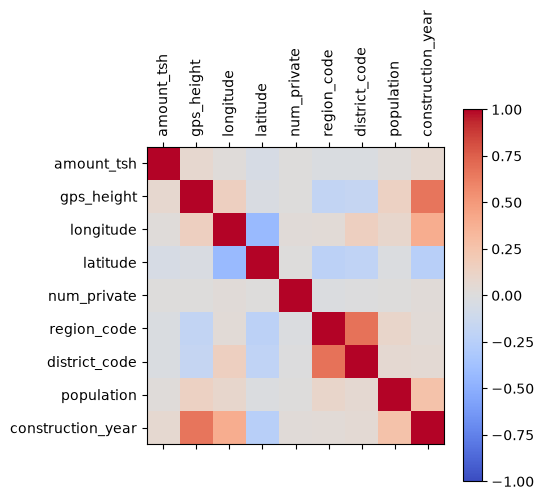

,amount_tsh,gps_height,longitude,latitude,num_private,region_code,district_code,population,construction_year
amount_tsh,1.00,0.08,0.02,-0.05,0.00,-0.03,-0.02,0.02,0.07
gps_height,0.08,1.00,0.15,-0.04,0.01,-0.18,-0.17,0.14,0.66
longitude,0.02,0.15,1.00,-0.43,0.02,0.03,0.15,0.09,0.40
latitude,-0.05,-0.04,-0.43,1.00,0.01,-0.22,-0.20,-0.02,-0.25
num_private,0.00,0.01,0.02,0.01,1.00,-0.02,-0.00,0.00,0.03
region_code,-0.03,-0.18,0.03,-0.22,-0.02,1.00,0.68,0.09,0.03
district_code,-0.02,-0.17,0.15,-0.20,-0.00,0.68,1.00,0.06,0.05
population,0.02,0.14,0.09,-0.02,0.00,0.09,0.06,1.00,0.26
construction_year,0.07,0.66,0.40,-0.25,0.03,0.03,0.05,0.26,1.00


In [13]:
corr = df[num].corr()
plt.matshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(num)), num, rotation=90)
plt.yticks(range(len(num)), num)
plt.colorbar()
plt.show()
corr.round(2)

## 1.9 Colonnes catégorielles redondantes

In [14]:
# Si chaque valeur de A donne une seule valeur de B, B répète A
paires = [("quantity", "quantity_group"), ("payment", "payment_type"),
          ("water_quality", "quality_group"), ("source", "source_type"),
          ("waterpoint_type", "waterpoint_type_group"), ("extraction_type", "extraction_type_group")]
for a, b in paires:
    print(a, "->", b, ":", df.groupby(a)[b].nunique().max())

quantity -> quantity_group : 1
payment -> payment_type : 1
water_quality -> quality_group : 1
source -> source_type : 1
waterpoint_type -> waterpoint_type_group : 1
extraction_type -> extraction_type_group : 1


## 1.10 Lien avec l'état

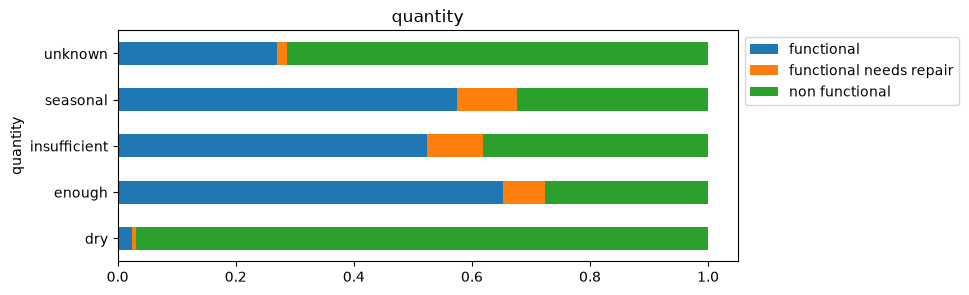

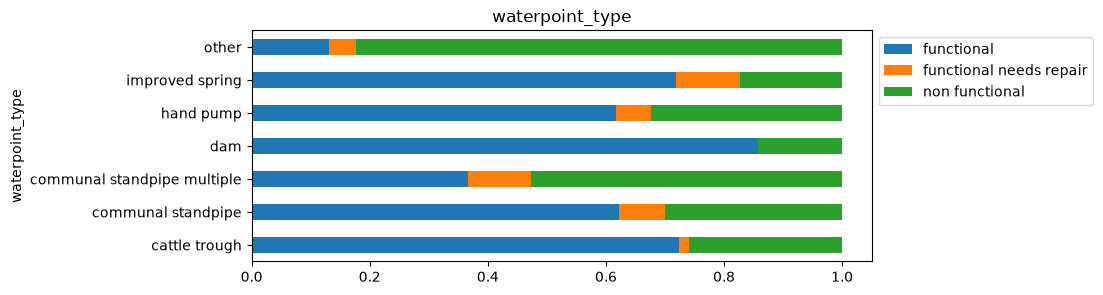

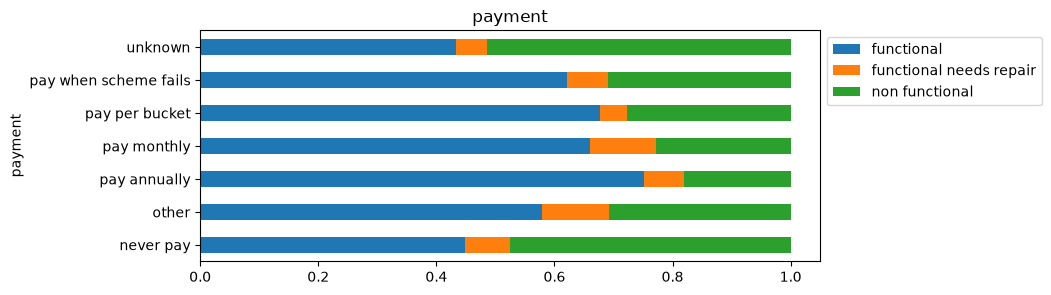

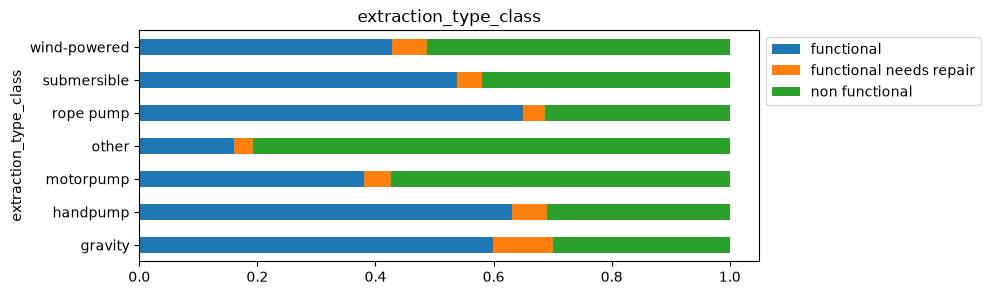

In [15]:
for c in ["quantity", "waterpoint_type", "payment", "extraction_type_class"]:
    pd.crosstab(df[c], df["status_group"], normalize="index").plot.barh(stacked=True, figsize=(8, 3), title=c)
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()

## 1.11 Constats

1. Classes déséquilibrées : 7 % seulement à réparer.
2. Des zéros qui veulent dire « inconnu » (année, population, altitude, longitude).
3. Des textes qui veulent dire « inconnu » et des valeurs écrites de plusieurs façons.
4. Des colonnes inutiles, à trop de modalités ou en double.
5. Quelques lignes en double et des dates incohérentes.
6. La quantité d'eau est la variable la plus liée à l'état.

# Partie 2 : traitement des données

## 2.1 Supprimer les lignes en double

In [16]:
import numpy as np

avant = len(df)
df = df.drop_duplicates(subset=df.columns.drop("id"))
print(avant - len(df), "lignes supprimées")

36 lignes supprimées


## 2.2 Mettre les textes en minuscules

In [17]:
for c in cat:
    df[c] = df[c].apply(lambda v: v.lower().strip() if isinstance(v, str) else v)

## 2.3 Remplacer les faux manquants

In [18]:
df[cat] = df[cat].replace(["0", "-", "unknown", "none"], np.nan)

for c in ["construction_year", "population", "gps_height", "longitude", "latitude"]:
    df[c] = df[c].replace(0, np.nan)
df.loc[df["longitude"].isna(), "latitude"] = np.nan   # latitude ≈ 0 quand longitude = 0

## 2.4 Créer l'âge du point d'eau

In [19]:
df["annee_releve"] = pd.to_datetime(df["date_recorded"]).dt.year
df["age"] = df["annee_releve"] - df["construction_year"]
df.loc[df["age"] < 0, "age"] = np.nan

## 2.5 Supprimer les colonnes inutiles

In [20]:
df = df.drop(columns=[
    "recorded_by",             # une seule valeur
    "num_private",             # presque toujours 0
    "wpt_name", "subvillage",  # des dizaines de milliers de modalités
    "scheme_name",             # moitié manquante
    "quantity_group", "payment_type", "quality_group", "source_type",
    "waterpoint_type_group", "extraction_type_group",  # copies d'autres colonnes
    "region_code",             # redondant avec region
    "date_recorded",           # remplacée par annee_releve
])
df.shape

(59364, 30)

## 2.6 Manquants catégoriels : « inconnu »

In [21]:
cat = df.select_dtypes(exclude="number").columns.drop("status_group")
df[cat] = df[cat].fillna("inconnu")

## 2.7 Manquants numériques restants

In [22]:
# Remplacés après le découpage, par la médiane du train (partie 3)
manq = df.isna().sum()
manq[manq > 0]

gps_height           20402
longitude             1777
latitude              1777
population           21345
construction_year    20673
age                  20682
dtype: int64

# Partie 3 : découpage apprentissage / validation / test

## 3.1 Un lieu par point d'eau

In [23]:
# Les points aux mêmes coordonnées partagent un lieu ; sans coordonnées, chaque point est seul
df["lieu"] = df["longitude"].astype(str) + "/" + df["latitude"].astype(str)
df.loc[df["longitude"].isna(), "lieu"] = df["id"].astype(str)

## 3.2 Découpage 70 / 15 / 15 des lieux

In [24]:
from sklearn.model_selection import train_test_split

lieux = df.drop_duplicates("lieu")
l_train, l_reste = train_test_split(lieux, test_size=0.30, stratify=lieux["status_group"], random_state=42)
l_val, l_test = train_test_split(l_reste, test_size=0.50, stratify=l_reste["status_group"], random_state=42)

train = df[df["lieu"].isin(l_train["lieu"])]
val = df[df["lieu"].isin(l_val["lieu"])]
test = df[df["lieu"].isin(l_test["lieu"])]
print(len(train), len(val), len(test))

41564 8901 8899


## 3.3 Vérifications

In [25]:
for nom, part in [("train", train), ("val", val), ("test", test)]:
    print(nom, part["status_group"].value_counts(normalize=True).round(3).to_dict())

print("Lieux communs :", len(set(train["lieu"]) & set(val["lieu"])), len(set(train["lieu"]) & set(test["lieu"])))

train {'functional': 0.543, 'non functional': 0.384, 'functional needs repair': 0.073}
val {'functional': 0.543, 'non functional': 0.384, 'functional needs repair': 0.073}
test {'functional': 0.543, 'non functional': 0.384, 'functional needs repair': 0.073}
Lieux communs : 0 0


## 3.4 Manquants numériques : médiane du train

In [26]:
mediane = train.drop(columns="id").median(numeric_only=True)
train = train.fillna(mediane)
val = val.fillna(mediane)
test = test.fillna(mediane)
mediane.round(1)

amount_tsh              0.0
gps_height           1166.0
longitude              35.0
latitude               -5.2
district_code           3.0
population            150.0
construction_year    2000.0
annee_releve         2012.0
age                    13.0
dtype: float64

## 3.5 Enregistrement

In [27]:
# Découpage figé : chaque id avec sa part
split = pd.concat([train.assign(part="train"), val.assign(part="val"), test.assign(part="test")])
split[["id", "part"]].to_csv("../data/livrable2/split.csv", index=False)

train.to_csv("../data/livrable2/train.csv", index=False)
val.to_csv("../data/livrable2/val.csv", index=False)
test.to_csv("../data/livrable2/test.csv", index=False)  # mis de côté jusqu'à la séance 5